In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import pandas as pd
from aqs import awareness as A, features as F, plots as P, stats as S
from aqs.config import CITIES, PROCESSED

pd.set_option("display.precision", 3)
pd.set_option("display.max_rows", 100)
P.use_theme()
long = F.load_long()

In [2]:
pd.concat({c: A.level_vs_surprise(F.attention_pair(long, c)) for c in CITIES})

effect    low   high          p
bangkok   expected   0.750  0.519  0.982  2.057e-10
          surprise   0.665  0.369  0.960  1.023e-05
krakow    expected   1.107  0.838  1.375  5.969e-16
          surprise   0.463  0.208  0.719  3.784e-04
melbourne expected  -2.075 -4.573  0.422  1.034e-01
          surprise   0.267 -0.586  1.120  5.395e-01
lahore    expected   0.046  0.010  0.082  1.191e-02
          surprise   0.098 -0.021  0.218  1.073e-01

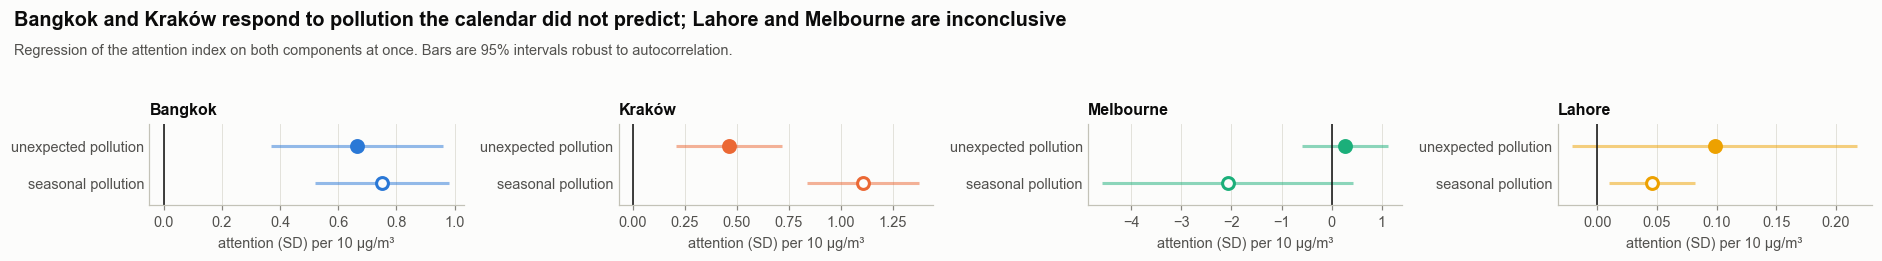

In [3]:
P.level_vs_surprise_plot(long);

In [4]:
pd.DataFrame({c: A.attention_threshold(F.attention_pair(long, c)) for c in CITIES}).T

,threshold,low,high,base,slope_per_10,aic_gain_vs_linear
bangkok,21.907,12.926,34.950,-0.485,0.993,1.817
krakow,8.035,7.664,18.149,-0.773,0.770,-2.008
melbourne,7.145,3.893,8.226,0.067,-1.612,1.218
lahore,244.571,41.434,289.714,-0.219,0.225,33.509


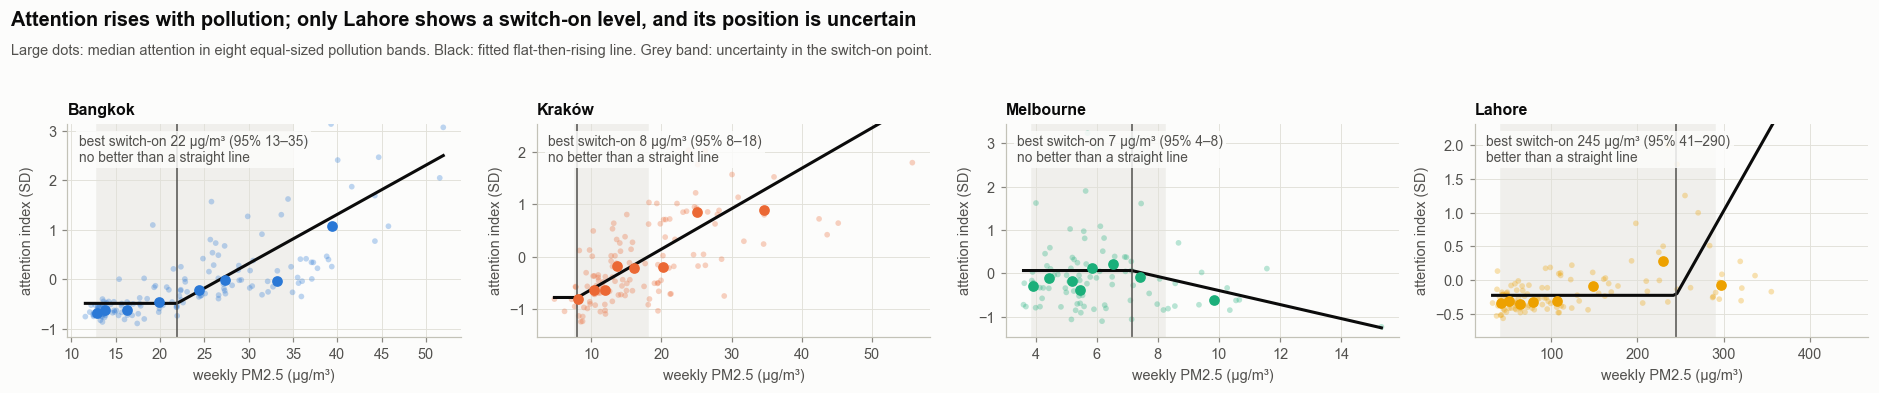

In [5]:
P.dose_response(long);

In [6]:
pd.DataFrame({c: A.episode_response(F.attention_pair(long, c))["summary"] for c in CITIES}).T

,episodes,peak_week,peak_response,peak_low,peak_high,weeks_to_half
bangkok,6.0,1.0,0.973,-0.624,3.394,1.0
krakow,6.0,0.0,0.545,-0.431,1.895,1.0
melbourne,5.0,8.0,0.147,-0.084,0.460,NaN
lahore,6.0,1.0,1.482,-0.401,4.202,1.0


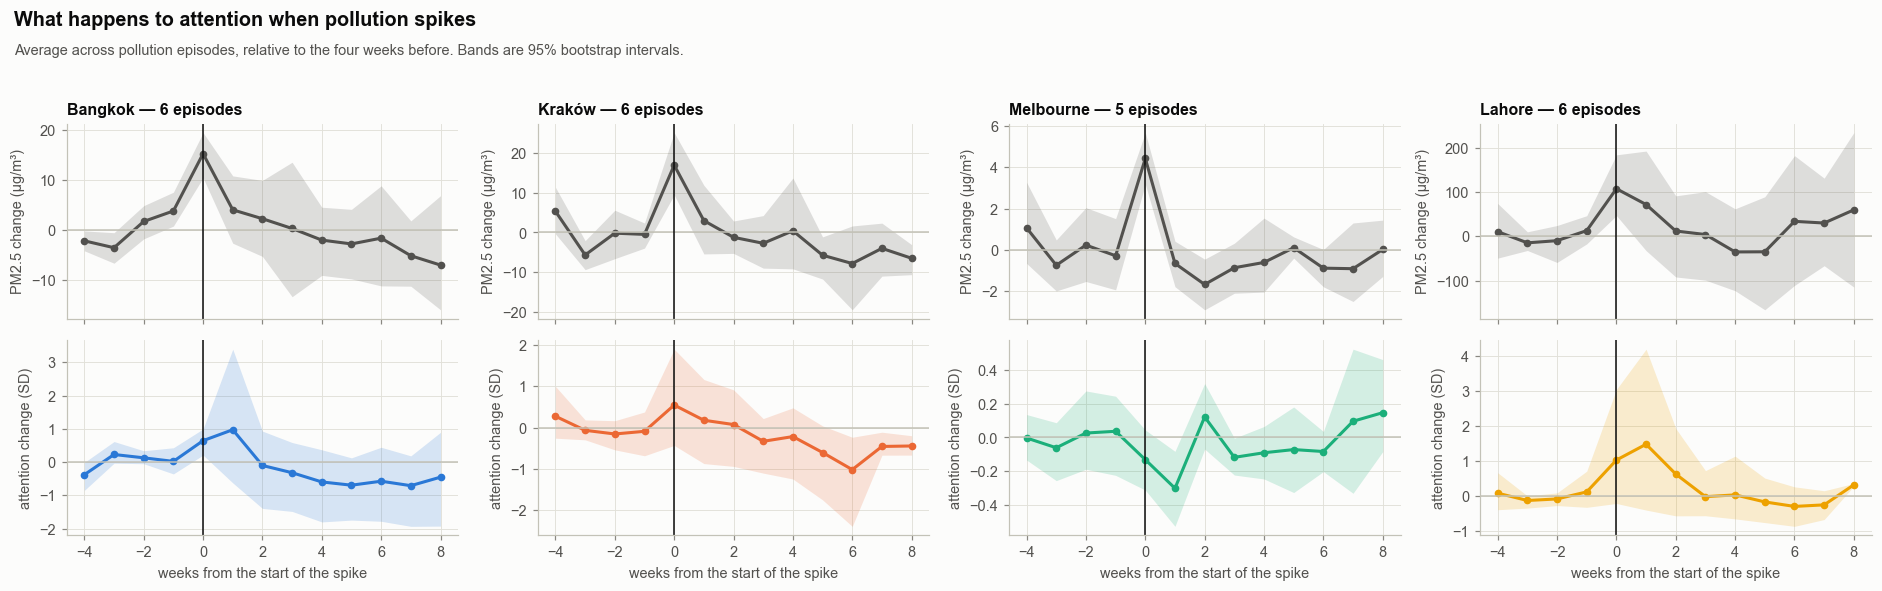

In [7]:
P.episode_curves(long);

In [8]:
pd.concat({c: A.lag_asymmetry(F.attention_pair(long, c)) for c in CITIES}).droplevel(1).set_index(
    ["horizon", "direction"], append=True)

weeks       mean    low   high
          horizon direction                                           
bangkok   0       rising                   78  1.134e-01 -0.073  0.400
                  falling                  70 -1.316e-01 -0.300  0.095
                  rising minus falling    148  2.450e-01  0.046  0.523
          1       rising                   76  1.032e-02 -0.132  0.226
                  falling                  70 -5.005e-02 -0.227  0.225
                  rising minus falling    146  6.037e-02 -0.172  0.290
          2       rising                   74 -3.884e-02 -0.168  0.152
                  falling                  70 -1.479e-02 -0.193  0.244
                  rising minus falling    144 -2.405e-02 -0.263  0.177
          3       rising                   74  3.542e-02 -0.128  0.289
                  falling                  68 -1.013e-01 -0.234  0.094
                  rising minus falling    142  1.368e-01 -0.066  0.382
krakow    0       rising                   62  8.912e-02 -0.043  0.212
                  falling                  66 -1.154e-01 -0.205  0.016
                  rising minus falling    128  2.045e-01  0.059  0.285
          1       rising                   59 -6.037e-02 -0.147  0.059
                  falling                  63  8.726e-03 -0.130  0.157
                  rising minus falling    122 -6.910e-02 -0.183  0.051
          2       rising                   57  9.853e-03 -0.135  0.190
                  falling                  61 -3.360e-02 -0.140  0.067
                  rising minus falling    118  4.345e-02 -0.062  0.200
          3       rising                   57  1.767e-02 -0.128  0.202
                  falling                  58 -7.385e-02 -0.199  0.054
                  rising minus falling    115  9.152e-02 -0.062  0.281
melbourne 0       rising                   44  1.758e-04 -0.258  0.125
                  falling                  49 -2.496e-02 -0.276  0.132
                  rising minus falling     93  2.514e-02 -0.136  0.111
          1       rising                   44 -4.273e-02 -0.262  0.065
                  falling                  46 -7.116e-02 -0.310  0.099
                  rising minus falling     90  2.843e-02 -0.132  0.134
          2       rising                   42 -2.595e-02 -0.325  0.140
                  falling                  46 -1.258e-01 -0.289  0.007
                  rising minus falling     88  9.990e-02 -0.098  0.235
          3       rising                   42 -8.052e-02 -0.358  0.085
                  falling                  44 -1.106e-01 -0.296  0.066
                  rising minus falling     86  3.006e-02 -0.177  0.201
lahore    0       rising                   54  2.557e-02 -0.166  0.243
                  falling                  56  5.564e-04 -0.195  0.236
                  rising minus falling    110  2.501e-02 -0.101  0.202
          1       rising                   51  2.168e-01 -0.073  0.671
                  falling                  49 -1.532e-01 -0.293 -0.018
                  rising minus falling    100  3.701e-01  0.056  0.835
          2       rising                   47  2.586e-01 -0.101  0.813
                  falling                  46 -1.574e-01 -0.316  0.015
                  rising minus falling     93  4.159e-01 -0.013  1.052
          3       rising                   47  2.159e-01 -0.138  0.690
                  falling                  42 -1.719e-01 -0.319 -0.020
                  rising minus falling     89  3.878e-01  0.004  0.900

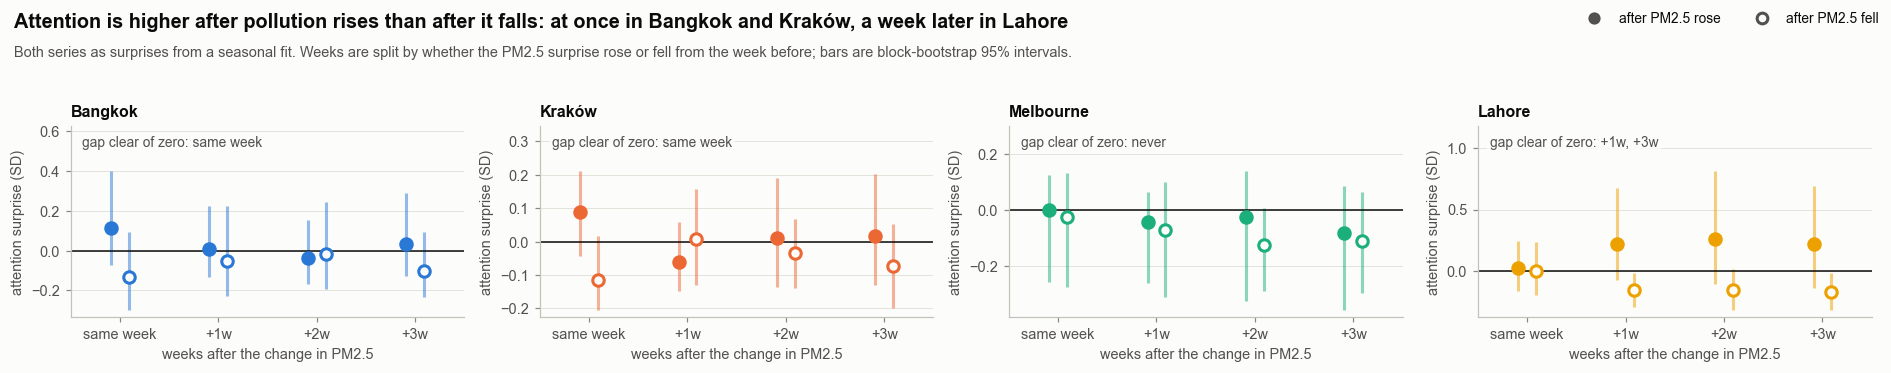

In [9]:
P.lag_asymmetry_plot(long);

In [10]:
pd.DataFrame({c: A.habituation(F.attention_pair(long, c), c) for c in CITIES}).T

,high_weeks,effect_per_week,low,high,p,leave_one_season_min,leave_one_season_max
bangkok,50.0,0.070,0.034,0.106,1.567e-04,0.053,0.089
krakow,45.0,-0.051,-0.089,-0.013,8.214e-03,-0.124,-0.039
melbourne,32.0,-0.051,-0.238,0.136,5.934e-01,-0.077,0.001
lahore,41.0,-0.091,-0.191,0.009,7.491e-02,-0.144,-0.040


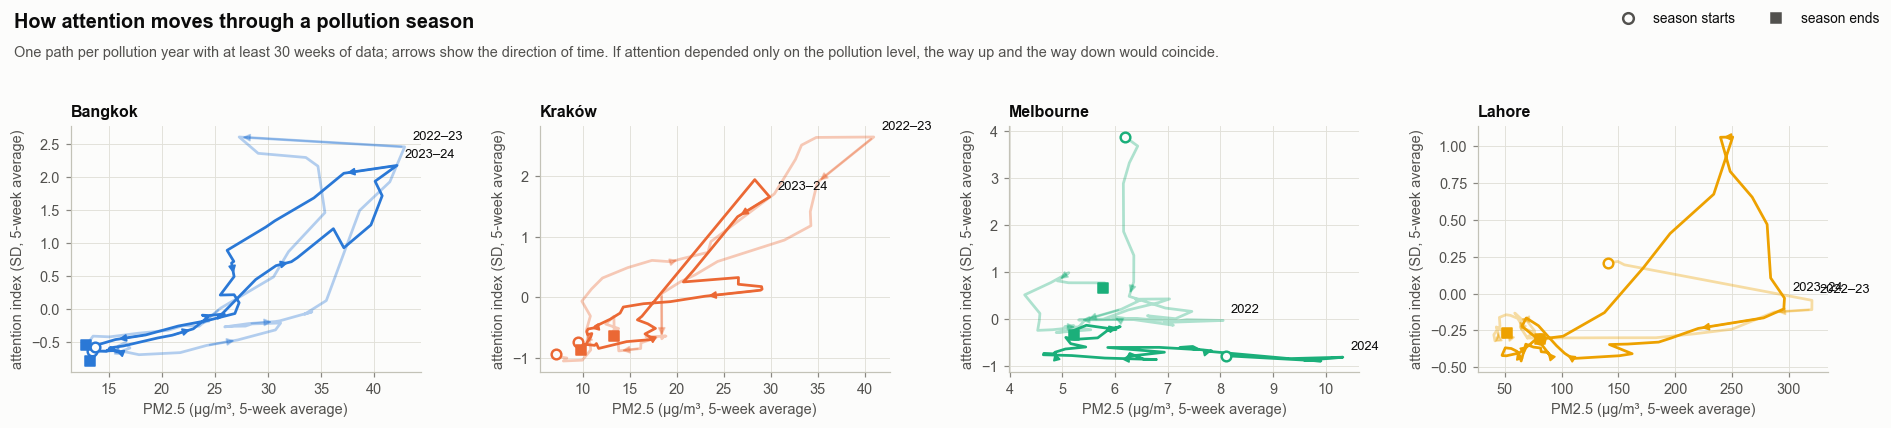

In [11]:
P.hysteresis(long);

In [12]:
pd.DataFrame({c: A.silent_weeks(F.attention_pair(long, c), c)[1] for c in CITIES}).T

,high_weeks,silent_weeks,silent_share,low,high,silent_share_early,silent_share_late
bangkok,50.0,1.0,0.020,0.000,0.060,0.043,0.000
krakow,45.0,4.0,0.089,0.022,0.200,0.050,0.120
melbourne,32.0,16.0,0.500,0.188,0.906,0.562,0.438
lahore,41.0,7.0,0.171,0.049,0.341,0.100,0.238


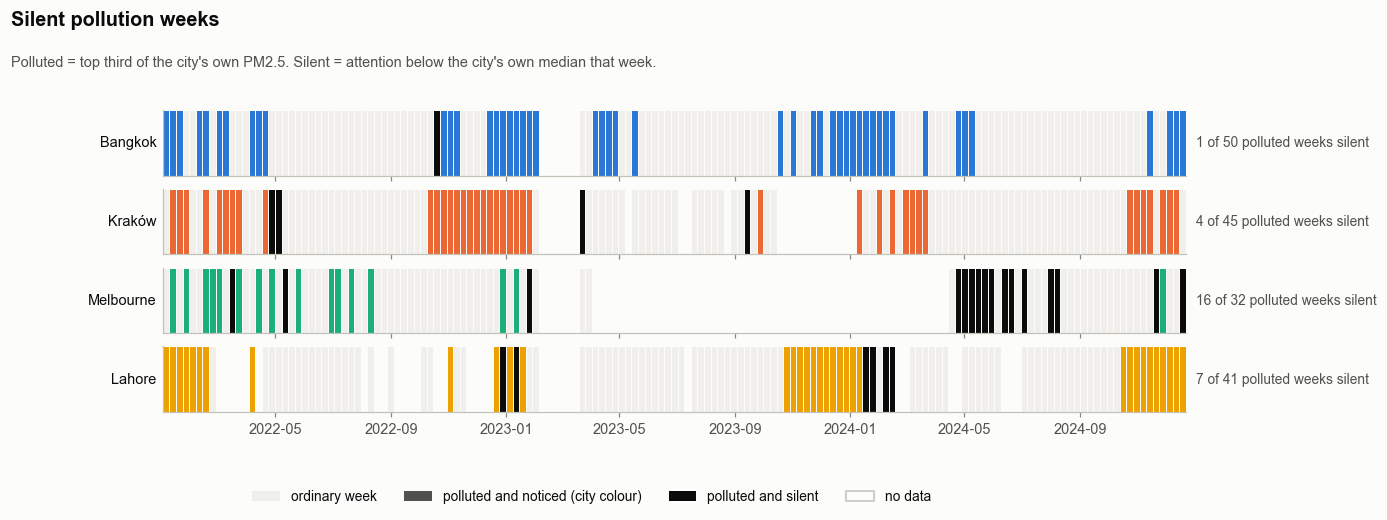

In [13]:
P.silent_strips(long);

In [14]:
A.scorecard(long).T.round(2)

city,bangkok,krakow,melbourne,lahore
surprise_effect,0.66,0.46,0.27,0.10
surprise_p,0.00,0.00,0.54,0.11
expected_effect,0.75,1.11,-2.08,0.05
expected_p,0.00,0.00,0.10,0.01
threshold,21.91,8.04,7.15,244.57
threshold_low,12.93,7.66,3.89,41.43
threshold_high,34.95,18.15,8.23,289.71
threshold_aic_gain,1.82,-2.01,1.22,33.51
episodes,6.00,6.00,5.00,6.00
peak_week,1.00,0.00,8.00,1.00
